# Tiny ML for Microsecond Order Book Mid-Price Prediction (NIFTY futures)

**Goal:** predict the short-term direction of the order-book mid-price (down / flat / up) for NIFTY near-month futures with models small and fast enough to sit in a high-frequency trading loop.

**Pipeline:** load the 5-level order book → clean → compute 18 microstructure features **with one streaming (per-tick) function** → make DeepLOB-style labels → train tiny models → re-implement each one as a `numba` kernel → measure accuracy, latency (µs), size and reliability.

**Data:**
* **Real:** `python collect_kite.py` (Zerodha) or `python collect_upstox.py` (Upstox) records the NIFTY near-month futures 5-level order book to `data/nifty_fut_YYYYMMDD.csv`. The notebook uses those files automatically once they hold at least 5,000 snapshots.
* **Synthetic stand-in:** with no recorded files, a small order-book simulator generates data so the notebook runs end to end. Synthetic results show that the pipeline works. They say nothing about real NIFTY predictability.

**Note on "microsecond":** broker feeds deliver snapshot ticks (several per second), not exchange tick-by-tick messages. "Microsecond" here refers to **inference latency** (features + model per tick), not to the data's time resolution.

Nothing in this notebook places orders. Predictions are only evaluated offline.

In [1]:
import glob, json, time, copy
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import numba as nb
import torch
import torch.nn as nn
import torch.nn.functional as TF
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, f1_score, confusion_matrix

import tinyml as tm   # shared core: features, labels, simulator, integer-only model, C export
from tinyml import (LEVELS, BOOK_COLS, FEATURES, NF, W, MW, OR, MR, ST_SIZE,
                    simulate_lob, feat_update, run_features, future_move)

SEED = 0
np.random.seed(SEED); torch.manual_seed(SEED)
HORIZONS = [10, 50]          # prediction horizons, in book updates
H_MAIN = HORIZONS[0]         # horizon used for latency / reliability deep-dive
RES, MOD = Path("results"), Path("models")
RES.mkdir(exist_ok=True); MOD.mkdir(exist_ok=True)

CLASSES = ["down", "flat", "up"]
COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]  # fixed categorical order
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.25, "lines.linewidth": 2})

## 1. Data: recorded NIFTY sessions, or the synthetic simulator

The simulator is an event-driven 5-level book on a tick grid. Market orders, limit adds and cancels arrive with a hidden, persistent buy/sell pressure. A touch queue that empties moves the price. This gives the real mechanism that microstructure features exploit: queue imbalance and order-flow imbalance (OFI) lead mid-price moves. Each snapshot bundles 1–5 events, as broker ticks do.

In [2]:
MIN_ROWS = 5000   # below this, recorded data is too short to train/validate/test on
files = sorted(glob.glob("data/nifty_fut_*.csv"))
real = pd.concat([pd.read_csv(f).assign(session=i) for i, f in enumerate(files)], ignore_index=True) if files else None
if real is not None and len(real) >= MIN_ROWS:
    SOURCE, df = "recorded", real
    meta = Path("data/meta.json")
    TICK = float(json.loads(meta.read_text())["tick_size"]) if meta.exists() else 0.05
else:
    SOURCE, TICK = "synthetic", 0.05
    df = simulate_lob(tick=TICK)

print(f"DATA SOURCE: {SOURCE.upper()}  |  {len(df):,} snapshots, {df.session.nunique()} session(s), tick={TICK}")
if SOURCE == "synthetic":
    have = 0 if real is None else len(real)
    print(f"Recorded rows: {have:,} (< {MIN_ROWS:,}): using the simulator. "
          "Record with collect_kite.py or collect_upstox.py during market hours for real NIFTY data.")

DATA SOURCE: SYNTHETIC  |  240,000 snapshots, 4 session(s), tick=0.05
Recorded rows: 4,766 (< 5,000): using the simulator. Record with collect_kite.py or collect_upstox.py during market hours for real NIFTY data.


## 2. Preprocessing
Drop invalid books (zero, one-sided, crossed or locked) and consecutive snapshots that change nothing (identical book and volume). Each session is processed on its own, so no feature or label spans two days.

kept 240,000 / 240,000 snapshots after cleaning


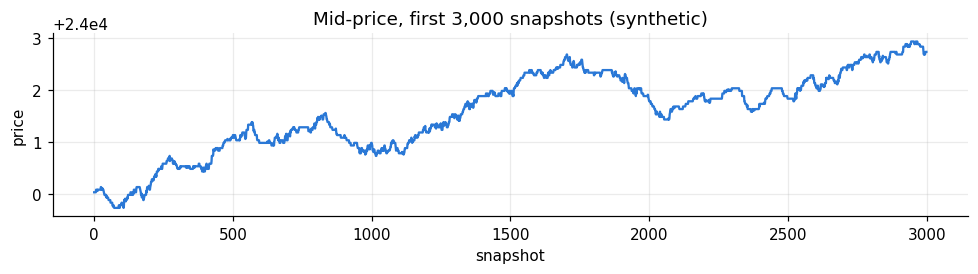

In [3]:
def clean(df):
    ok = (df.bp1 > 0) & (df.ap1 > 0) & (df.ap1 > df.bp1) & (df.bq1 > 0) & (df.aq1 > 0)
    df = df[ok]
    same = (df[BOOK_COLS].diff().abs().sum(axis=1) == 0) & (df.session == df.session.shift())
    return df[~same].reset_index(drop=True)

n0 = len(df)
df = clean(df)
print(f"kept {len(df):,} / {n0:,} snapshots after cleaning")

g0 = df[df.session == df.session.iloc[0]].iloc[:3000]
fig, ax = plt.subplots(figsize=(9, 2.6))
ax.plot((g0.bp1 + g0.ap1) / 2, color=COLORS[0], lw=1.5)
ax.set(title=f"Mid-price, first 3,000 snapshots ({SOURCE})", xlabel="snapshot", ylabel="price")
plt.tight_layout(); plt.savefig(RES / "mid_sample.png"); plt.show()

## 3. Microstructure features (one streaming implementation)

The features come from **one `numba` function that updates per tick**, `tinyml.feat_update(state, row) -> x` (a bit-identical C port is in `c/tinyml_features.h`). The same function builds the training set (run over history) and serves live inference. So there is no train/serve skew, and look-ahead is impossible by construction: each row sees only the past.

| # | feature | meaning |
|---|---|---|
| 0 | spread | ask1 − bid1, in ticks |
| 1 | micro | microprice − mid, in ticks |
| 2–4 | imb1, imb3, imb5 | queue imbalance using levels 1, 1–3, 1–5 |
| 5–7 | ofi1, ofi5, ofi20 | order-flow imbalance (Cont–Kukanov–Stoikov) summed over the last 1/5/20 updates |
| 8–10 | ret1, ret5, ret20 | mid change over the last 1/5/20 updates, in ticks |
| 11 | rvol20 | std of 1-step mid changes over 20 updates |
| 12 | vold | log(1 + traded volume since the last update) |
| 13 | tbq_imb | total buy vs sell pending quantity imbalance |
| 14 | since_move | log(1 + updates since the mid last changed), capped at 100 |
| 15–16 | ofi_deep, ofi_deep5 | multi-level OFI: the same flow measure at levels 2–5, now and over the last 5 updates |
| 17 | svol5 | tick-rule signed volume: traded volume signed by the direction the mid moved, last 5 updates (signed log) |

In [4]:
Xs, Ds, Rs, Ss = [], {h: [] for h in HORIZONS}, [], []
for s, g in df.groupby("session", sort=True):
    R = g[BOOK_COLS].to_numpy(np.float64)
    X = run_features(R, TICK)
    m = 0.5 * (R[:, 0] + R[:, 10]) / TICK
    for h in HORIZONS:
        d = future_move(m, h)
        if len(m) > h + 5:   # label check against the plain definition
            assert np.isclose(d[5], m[6:6 + h].mean() - m[5])
        Ds[h].append(d)
    warm = np.arange(len(R)) >= W                     # drop warm-up rows with partial windows
    Xs.append(X); Rs.append(R); Ss.append(np.where(warm, s, -1))

X_raw = np.vstack(Xs); R_all = np.vstack(Rs); sess = np.concatenate(Ss)
D = {h: np.concatenate(Ds[h]) for h in HORIZONS}
valid = (sess >= 0) & np.all([np.isfinite(D[h]) for h in HORIZONS], axis=0)
X_raw, R_all, sess = X_raw[valid], R_all[valid], sess[valid]
D = {h: D[h][valid] for h in HORIZONS}

# no look-ahead: features of a truncated history equal the full-history features
k = min(5000, len(Rs[0]))
assert np.allclose(run_features(Rs[0][:k], TICK)[-1], run_features(Rs[0], TICK)[k - 1])
assert np.all(np.abs(X_raw[:, 2:5]) <= 1 + 1e-12) and np.all(X_raw[:, 0] > 0) and np.isfinite(X_raw).all()

pd.DataFrame(X_raw, columns=FEATURES).describe().T[["mean", "std", "min", "max"]].round(3)

,mean,std,min,max
spread,1.246,0.558,1.000,8.000
micro,-0.001,0.380,-2.833,2.769
imb1,-0.002,0.552,-0.976,0.975
imb3,-0.000,0.415,-0.982,0.977
imb5,-0.001,0.318,-0.967,0.940
ofi1,0.248,445.417,-3075.000,2925.000
ofi5,1.263,1289.747,-6075.000,5550.000
ofi20,5.434,3579.339,-12675.000,12375.000
ret1,-0.000,0.474,-4.000,3.500
ret5,-0.001,1.098,-6.000,6.500


## 4. Labels and the chronological split

DeepLOB / FI-2010 style: compare the **mean mid over the next h updates** with the current mid. Moves beyond ±α ticks are *up* or *down*, the rest *flat*. α is the ⅓-quantile of |move| on the **training** split, so the three classes are roughly balanced. The split is chronological (70 / 15 / 15) with no shuffling, so the test set is strictly in the future.

In [5]:
N = len(X_raw)
i1, i2 = int(0.70 * N), int(0.85 * N)
tr, va, te = slice(0, i1), slice(i1, i2), slice(i2, N)

mu, sd = X_raw[tr].mean(0), X_raw[tr].std(0) + 1e-9
Xz = (X_raw - mu) / sd
Xz32 = Xz.astype(np.float32)

Y, ALPHA = {}, {}
for h in HORIZONS:
    a = float(np.quantile(np.abs(D[h][tr]), 1 / 3))
    ALPHA[h] = a
    Y[h] = (1 + (D[h] > a).astype(int) - (D[h] < -a).astype(int))
    dist = np.bincount(Y[h][te], minlength=3) / len(Y[h][te])
    print(f"h={h:>3}: alpha={a:.3f} ticks | test class mix down/flat/up = {np.round(dist, 3)}")
print(f"train {i1:,} | val {i2 - i1:,} | test {N - i2:,} rows")

h= 10: alpha=0.350 ticks | test class mix down/flat/up = [0.332 0.339 0.329]
h= 50: alpha=1.030 ticks | test class mix down/flat/up = [0.336 0.328 0.336]
train 167,804 | val 35,958 | test 35,958 rows


## 5. Tiny models
* **Baselines:** majority class; *persistence* (the last mid move continues).
* **Logistic regression:** 48 parameters.
* **Decision tree:** depth ≤ 6.
* **MLP** 18→8→8→3 (243 parameters; width 8 chosen by the size–speed search in section 13), trained in PyTorch with early stopping on validation loss.
* **MLP int8:** the same MLP with per-tensor symmetric int8 weights (4× smaller), int32-style accumulation, then rescaled.

In [6]:
HIDDEN = 8   # width chosen by the size-speed search (section 13): 8 matches 16 at half the bytes


def train_mlp(Xtr, ytr, Xva, yva, epochs=40, patience=4, bs=1024):
    torch.manual_seed(SEED)
    net = nn.Sequential(nn.Linear(NF, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, HIDDEN), nn.ReLU(), nn.Linear(HIDDEN, 3))
    opt = torch.optim.Adam(net.parameters(), lr=3e-3, weight_decay=1e-4)
    Xt, yt = torch.from_numpy(Xtr), torch.from_numpy(ytr).long()
    Xv, yv = torch.from_numpy(Xva), torch.from_numpy(yva).long()
    best, bad, state = np.inf, 0, None
    for _ in range(epochs):
        net.train()
        perm = torch.randperm(len(Xt))
        for i in range(0, len(Xt), bs):
            idx = perm[i:i + bs]
            opt.zero_grad(); TF.cross_entropy(net(Xt[idx]), yt[idx]).backward(); opt.step()
        net.eval()
        with torch.no_grad():
            vl = TF.cross_entropy(net(Xv), yv).item()
        if vl < best - 1e-4:
            best, bad, state = vl, 0, copy.deepcopy(net.state_dict())
        else:
            bad += 1
            if bad >= patience: break
    net.load_state_dict(state)
    return net.eval()


def mlp_weights(net):
    return [p.detach().numpy().astype(np.float32).copy() for p in net.parameters()]   # W1,b1,W2,b2,W3,b3


def quantize(ws):
    """Per-tensor symmetric int8 for weight matrices; biases stay fp32."""
    out = []
    for W, b in zip(ws[0::2], ws[1::2]):
        s = np.float32(np.abs(W).max() / 127.0)
        out += [np.round(W / s).astype(np.int8), s, b]
    return out   # Wq1,s1,b1, Wq2,s2,b2, Wq3,s3,b3


def np_mlp(x, ws):
    h = x
    for i, (W, b) in enumerate(zip(ws[0::2], ws[1::2])):
        h = h @ W.T + b
        if i < 2: h = np.maximum(h, 0)
    return h


def deq(q):
    return [q[0].astype(np.float32) * q[1], q[2], q[3].astype(np.float32) * q[4], q[5], q[6].astype(np.float32) * q[7], q[8]]


def softmax(z):
    z = z - z.max(1, keepdims=True); e = np.exp(z); return e / e.sum(1, keepdims=True)


rows, preds, store = [], {}, {}
for h in HORIZONS:
    y = Y[h]
    P = {}
    P["majority"] = np.full(N - i2, np.bincount(y[tr]).argmax())
    r1 = X_raw[te, 8]
    P["persistence"] = np.where(r1 > 0, 2, np.where(r1 < 0, 0, 1))
    lr = LogisticRegression(max_iter=2000, C=1.0).fit(Xz[tr], y[tr])
    P["logreg"] = lr.predict(Xz[te])
    tree = DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, random_state=SEED).fit(Xz[tr], y[tr])
    P["tree_d6"] = tree.predict(Xz[te])
    net = train_mlp(Xz32[tr], y[tr], Xz32[va], y[va])
    ws = mlp_weights(net); q = quantize(ws)
    P["mlp_fp32"] = np_mlp(Xz32[te], ws).argmax(1)
    P["mlp_int8"] = np_mlp(Xz32[te], deq(q)).argmax(1)
    for name, p in P.items():
        rows.append({"model": name, "h": h, "accuracy": accuracy_score(y[te], p),
                     "macro_f1": f1_score(y[te], p, average="macro")})
    preds[h] = P
    store[h] = dict(lr=lr, tree=tree, net=net, ws=ws, q=q)

acc = pd.DataFrame(rows)
acc.pivot(index="model", columns="h", values=["accuracy", "macro_f1"]).round(4)

accuracy         macro_f1        
h                 10      50       10      50
model                                        
logreg        0.4775  0.4178   0.4732  0.4004
majority      0.3393  0.3276   0.1689  0.1645
mlp_fp32      0.4997  0.4275   0.4976  0.4129
mlp_int8      0.5003  0.4276   0.4981  0.4134
persistence   0.3734  0.3468   0.3415  0.3183
tree_d6       0.4846  0.4095   0.4835  0.3833

In [7]:
cm = confusion_matrix(Y[H_MAIN][te], preds[H_MAIN]["mlp_int8"], normalize="true")
print(f"MLP int8 confusion matrix (h={H_MAIN}, rows = true class, normalised):")
pd.DataFrame(cm, index=CLASSES, columns=CLASSES).round(3)

MLP int8 confusion matrix (h=10, rows = true class, normalised):


,down,flat,up
down,0.558,0.238,0.204
flat,0.298,0.395,0.307
up,0.224,0.225,0.551


## 6. Deployable inference: numba kernels

Each model is rewritten as a plain `@numba.njit` function on flat arrays, with no framework at inference time. Parity with sklearn and torch is asserted before any latency number is trusted.

In [8]:
@nb.njit
def lr_predict(x, W, b):
    best, bv = 0, -1e300
    for k in range(W.shape[0]):
        s = b[k]
        for j in range(x.shape[0]): s += W[k, j] * x[j]
        if s > bv: bv, best = s, k
    return best


@nb.njit
def tree_predict(x, feat, thr, left, right, leaf):
    n = 0
    while left[n] != -1:
        n = left[n] if x[feat[n]] <= thr[n] else right[n]
    return leaf[n]


@nb.njit
def dense(x, W, b, relu):
    out = np.empty(W.shape[0], np.float32)
    for i in range(W.shape[0]):
        s = b[i]
        for j in range(W.shape[1]): s += W[i, j] * x[j]
        out[i] = s if (s > 0 or not relu) else 0.0
    return out


@nb.njit
def dense_q(x, Wq, sc, b, relu):
    out = np.empty(Wq.shape[0], np.float32)
    for i in range(Wq.shape[0]):
        acc = np.float32(0.0)
        for j in range(Wq.shape[1]): acc += np.float32(Wq[i, j]) * x[j]
        s = acc * sc + b[i]
        out[i] = s if (s > 0 or not relu) else 0.0
    return out


@nb.njit
def mlp_logits(x, W1, b1, W2, b2, W3, b3):
    return dense(dense(dense(x, W1, b1, True), W2, b2, True), W3, b3, False)


@nb.njit
def mlp_predict(x, W1, b1, W2, b2, W3, b3):
    return np.argmax(mlp_logits(x, W1, b1, W2, b2, W3, b3))


@nb.njit
def mlpq_predict(x, Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3):
    return np.argmax(dense_q(dense_q(dense_q(x, Wq1, s1, b1, True), Wq2, s2, b2, True), Wq3, s3, b3, False))


S = store[H_MAIN]
LR_W, LR_b = S["lr"].coef_.astype(np.float64), S["lr"].intercept_.astype(np.float64)
t_ = S["tree"].tree_
TR = (t_.feature.astype(np.int16), t_.threshold.astype(np.float64), t_.children_left.astype(np.int16),
      t_.children_right.astype(np.int16), S["tree"].classes_[t_.value[:, 0, :].argmax(1)].astype(np.int8))
WS, Q = S["ws"], S["q"]
assert list(S["tree"].classes_) == [0, 1, 2] and list(S["lr"].classes_) == [0, 1, 2]

# parity checks on the whole test set
Xte, Xte32 = Xz[te], Xz32[te]
nb_lr = np.array([lr_predict(x, LR_W, LR_b) for x in Xte])
nb_tree = np.array([tree_predict(x, *TR) for x in Xte32])        # sklearn trees compare float32 features
nb_mlp = np.array([mlp_predict(x, *WS) for x in Xte32])
nb_mlpq = np.array([mlpq_predict(x, *Q) for x in Xte32])
with torch.no_grad():
    torch_logits = S["net"](torch.from_numpy(Xte32[:2000])).numpy()
nb_logits = np.array([mlp_logits(x, *WS) for x in Xte32[:2000]])
assert np.allclose(nb_logits, torch_logits, atol=1e-4)
for name, a_, b_ in [("logreg", nb_lr, preds[H_MAIN]["logreg"]), ("tree_d6", nb_tree, preds[H_MAIN]["tree_d6"]),
                     ("mlp_fp32", nb_mlp, preds[H_MAIN]["mlp_fp32"]), ("mlp_int8", nb_mlpq, preds[H_MAIN]["mlp_int8"])]:
    agree = (a_ == b_).mean()
    print(f"{name:9s} numba vs reference agreement: {agree:.5%}")
    assert agree >= 0.999
assert (nb_tree == preds[H_MAIN]["tree_d6"]).all()

logreg    numba vs reference agreement: 100.00000%
tree_d6   numba vs reference agreement: 100.00000%
mlp_fp32  numba vs reference agreement: 100.00000%
mlp_int8  numba vs reference agreement: 100.00000%


## 7. Latency

Two views:
* **Per-call from Python:** `perf_counter_ns` around one single-sample call, 100k calls after warm-up, reported as p50 / p99 / p99.9. This includes about 0.1–0.3 µs of Python→numba dispatch, which a C++ or numba event loop would not pay.
* **In-kernel:** one compiled loop over the test set, total time divided by rows. This is the pure compute cost per prediction.

The full tick pipeline measures **features + z-score + model** on raw order-book rows. That is the number that matters in a trading loop.

In [9]:
torch.set_num_threads(1)


@nb.njit
def tick_pipeline(st, r, tick, mu, sd, xb, xz, Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3):
    feat_update(st, r, tick, xb)
    for j in range(xb.shape[0]):
        xz[j] = (xb[j] - mu[j]) / sd[j]
    return mlpq_predict(xz, Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3)


@nb.njit
def loop_lr(X, W, b):
    o = 0
    for i in range(X.shape[0]): o += lr_predict(X[i], W, b)
    return o

@nb.njit
def loop_tree(X, f, t, l, r, lf):
    o = 0
    for i in range(X.shape[0]): o += tree_predict(X[i], f, t, l, r, lf)
    return o

@nb.njit
def loop_mlp(X, W1, b1, W2, b2, W3, b3):
    o = 0
    for i in range(X.shape[0]): o += mlp_predict(X[i], W1, b1, W2, b2, W3, b3)
    return o

@nb.njit
def loop_mlpq(X, Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3):
    o = 0
    for i in range(X.shape[0]): o += mlpq_predict(X[i], Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3)
    return o

@nb.njit
def loop_pipeline(R, tick, mu, sd, Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3):
    st = np.zeros(ST_SIZE); xb = np.empty(mu.shape[0]); xz = np.empty(mu.shape[0], np.float32)
    o = 0
    for i in range(R.shape[0]): o += tick_pipeline(st, R[i], tick, mu, sd, xb, xz, Wq1, s1, b1, Wq2, s2, b2, Wq3, s3, b3)
    return o


def bench(fn, xs, n=100_000, warm=2000):
    m = len(xs)
    for i in range(warm): fn(xs[i % m])
    out = np.empty(n, np.int64); pc = time.perf_counter_ns
    for i in range(n):
        x = xs[i % m]; t0 = pc(); fn(x); out[i] = pc() - t0
    return np.percentile(out, [50, 99, 99.9]) / 1000.0


def kernel_ns(fn, *args, reps=5):
    fn(*args)                                   # compile / warm
    best = np.inf
    for _ in range(reps):
        t0 = time.perf_counter_ns(); fn(*args); best = min(best, time.perf_counter_ns() - t0)
    return best / len(args[0])


st_b, xb_b, xz_b = np.zeros(ST_SIZE), np.empty(NF), np.empty(NF, np.float32)
R_te = R_all[te]

lat = {
    "timer overhead": bench(lambda x: None, Xte),
    "logreg (sklearn)": bench(lambda x: S["lr"].predict(x[None]), Xte, n=3000, warm=200),
    "tree_d6 (sklearn)": bench(lambda x: S["tree"].predict(x[None]), Xte, n=3000, warm=200),
    "logreg (numba)": bench(lambda x: lr_predict(x, LR_W, LR_b), Xte),
    "tree_d6 (numba)": bench(lambda x: tree_predict(x, *TR), Xte32),
    "mlp_fp32 (numba)": bench(lambda x: mlp_predict(x, *WS), Xte32),
    "mlp_int8 (numba)": bench(lambda x: mlpq_predict(x, *Q), Xte32),
    "pipeline: features+z+mlp_int8 (numba)": bench(lambda r: tick_pipeline(st_b, r, TICK, mu, sd, xb_b, xz_b, *Q), R_te),
}
with torch.no_grad():
    lat["mlp_fp32 (torch)"] = bench(lambda x: S["net"](torch.from_numpy(x[None])), Xte32, n=3000, warm=200)

kern = {
    "logreg (numba)": kernel_ns(loop_lr, Xte, LR_W, LR_b),
    "tree_d6 (numba)": kernel_ns(loop_tree, Xte32, *TR),
    "mlp_fp32 (numba)": kernel_ns(loop_mlp, Xte32, *WS),
    "mlp_int8 (numba)": kernel_ns(loop_mlpq, Xte32, *Q),
    "pipeline: features+z+mlp_int8 (numba)": kernel_ns(loop_pipeline, R_te, TICK, mu, sd, *Q),
}
latdf = pd.DataFrame(lat, index=["p50_us", "p99_us", "p99.9_us"]).T
latdf["in_kernel_ns"] = pd.Series(kern)
latdf.round(3)

,p50_us,p99_us,p99.9_us,in_kernel_ns
timer overhead,0.1,0.200,0.300,NaN
logreg (sklearn),40.4,106.806,296.427,NaN
tree_d6 (sklearn),54.8,119.515,213.304,NaN
logreg (numba),0.4,0.900,1.800,21.603
tree_d6 (numba),0.7,1.300,2.100,25.018
mlp_fp32 (numba),1.2,2.100,9.300,221.820
mlp_int8 (numba),1.7,2.200,8.500,253.151
pipeline: features+z+mlp_int8 (numba),1.6,3.000,7.400,461.755
mlp_fp32 (torch),25.1,42.703,213.506,NaN


## 8. Model size

In [10]:
def nbytes(arrs):
    return int(sum(np.asarray(a).nbytes for a in arrs))

size = pd.DataFrame({
    "params": [LR_W.size + LR_b.size, int(t_.node_count), sum(w.size for w in WS), sum(w.size for w in WS)],
    "bytes": [nbytes([LR_W.astype(np.float32), LR_b.astype(np.float32)]), nbytes(TR), nbytes(WS), nbytes(Q)],
}, index=["logreg", "tree_d6", "mlp_fp32", "mlp_int8"])
size["params"] = size["params"].astype(int)
print("(tree: params = nodes; bytes = feature/threshold/children/leaf arrays as served)")
size

(tree: params = nodes; bytes = feature/threshold/children/leaf arrays as served)


,params,bytes
logreg,57,228
tree_d6,127,1905
mlp_fp32,251,1004
mlp_int8,251,320


## 9. Reliability
* **Calibration:** does a stated 70% confidence come true about 70% of the time? Reported as the expected calibration error (ECE).
* **Selective prediction:** act only on the most confident predictions and see how accuracy rises as coverage falls. This is how a tiny model is used in practice: trade only when it is sure.
* **Stability:** accuracy across 10 consecutive test chunks, plus per-session accuracy when there are several sessions.

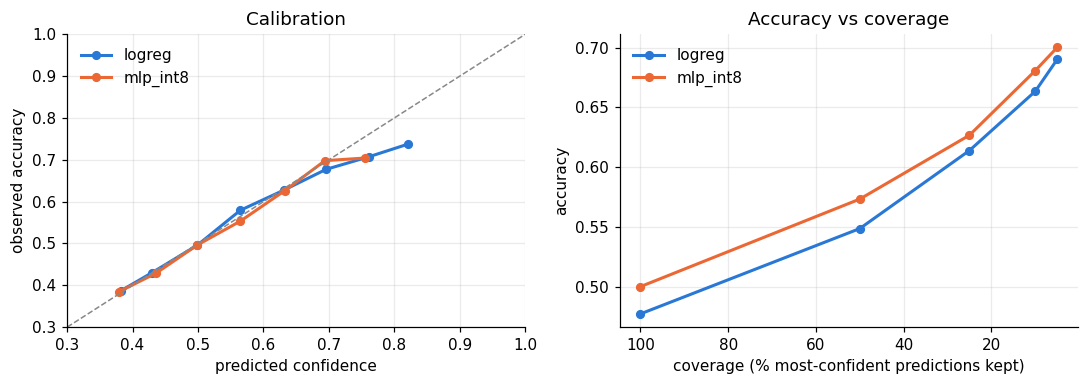

logreg    accuracy over 10 test chunks: mean 0.4775 ± 0.0127 (min 0.4566)
mlp_int8  accuracy over 10 test chunks: mean 0.5003 ± 0.0129 (min 0.4803)


,ECE,acc@100%,acc@50%,acc@25%,acc@10%,acc@5%
model,,,,,,
logreg,0.0055,0.4775,0.5488,0.6140,0.6634,0.6900
mlp_int8,0.0063,0.5003,0.5734,0.6268,0.6807,0.7001


In [11]:
yt = Y[H_MAIN][te]
probs = {"logreg": S["lr"].predict_proba(Xte), "mlp_int8": softmax(np_mlp(Xte32, deq(Q)))}

def ece(p, y, bins=10):
    conf, pred = p.max(1), p.argmax(1)
    e = 0.0; out = []
    edges = np.linspace(conf.min(), 1, bins + 1)
    for lo, hi in zip(edges[:-1], edges[1:]):
        m = (conf >= lo) & (conf < hi + 1e-12)
        if m.sum() > 50:
            out.append((conf[m].mean(), (pred[m] == y[m]).mean()))
            e += m.mean() * abs(conf[m].mean() - (pred[m] == y[m]).mean())
    return e, np.array(out)

COV = [1.0, 0.5, 0.25, 0.1, 0.05]
rel_rows = []
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
for c_, (name, p) in zip(COLORS, probs.items()):
    conf, pred = p.max(1), p.argmax(1)
    order = np.argsort(-conf)
    accs = [(pred[order[:int(c * len(conf))]] == yt[order[:int(c * len(conf))]]).mean() for c in COV]
    e, curve = ece(p, yt)
    rel_rows.append({"model": name, "ECE": e, **{f"acc@{int(c*100)}%": a for c, a in zip(COV, accs)}})
    axs[0].plot(curve[:, 0], curve[:, 1], "o-", color=c_, label=name, ms=5)
    axs[1].plot([c * 100 for c in COV], accs, "o-", color=c_, label=name, ms=5)
axs[0].plot([0, 1], [0, 1], color="#888", lw=1, ls="--")
axs[0].set(title="Calibration", xlabel="predicted confidence", ylabel="observed accuracy", xlim=(0.3, 1), ylim=(0.3, 1))
axs[1].set(title="Accuracy vs coverage", xlabel="coverage (% most-confident predictions kept)", ylabel="accuracy")
axs[1].invert_xaxis()
for a in axs: a.legend(frameon=False)
plt.tight_layout(); plt.savefig(RES / "reliability.png"); plt.show()

chunks = np.array_split(np.arange(len(yt)), 10)
stab = {name: [(p.argmax(1)[c] == yt[c]).mean() for c in chunks] for name, p in probs.items()}
for name, v in stab.items():
    print(f"{name:9s} accuracy over 10 test chunks: mean {np.mean(v):.4f} ± {np.std(v):.4f} (min {np.min(v):.4f})")
s_te = sess[te]
if len(np.unique(s_te)) > 1:
    for s in np.unique(s_te):
        m = s_te == s
        print(f"session {s}: mlp_int8 acc {(probs['mlp_int8'].argmax(1)[m] == yt[m]).mean():.4f} on {m.sum():,} rows")
pd.DataFrame(rel_rows).set_index("model").round(4)

## 10. Summary: accuracy vs latency vs size

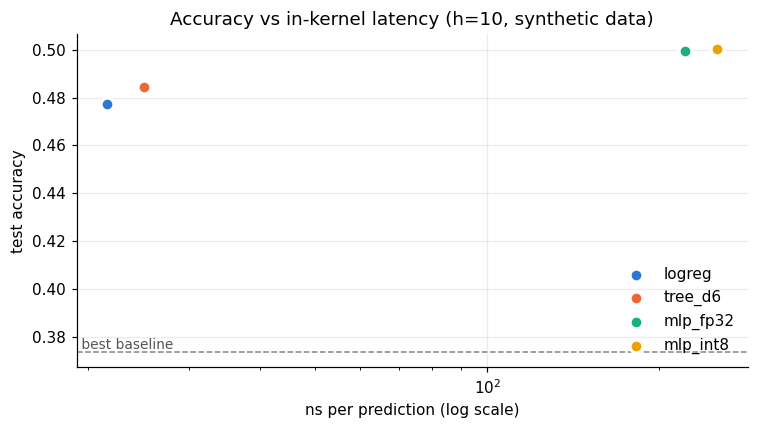

saved results/summary.csv, results/latency.csv, results/*.png, models/tinyml_midprice.npz


,accuracy_h10,macro_f1_h10,accuracy_h50,params,bytes,p50_us,p99_us,in_kernel_ns
model,,,,,,,,
majority,0.3393,0.1689,0.3276,NaN,NaN,NaN,NaN,NaN
persistence,0.3734,0.3415,0.3468,NaN,NaN,NaN,NaN,NaN
logreg,0.4775,0.4732,0.4178,57.0,228.0,0.4,0.9,21.6030
tree_d6,0.4846,0.4835,0.4095,127.0,1905.0,0.7,1.3,25.0181
mlp_fp32,0.4997,0.4976,0.4275,251.0,1004.0,1.2,2.1,221.8199
mlp_int8,0.5003,0.4981,0.4276,251.0,320.0,1.7,2.2,253.1509


In [12]:
name_map = {"logreg": "logreg (numba)", "tree_d6": "tree_d6 (numba)", "mlp_fp32": "mlp_fp32 (numba)", "mlp_int8": "mlp_int8 (numba)"}
summ = acc[acc.h == H_MAIN].set_index("model")[["accuracy", "macro_f1"]]
for h in HORIZONS[1:]:
    summ[f"accuracy_h{h}"] = acc[acc.h == h].set_index("model")["accuracy"]
summ = summ.join(size)
for m_, k_ in name_map.items():
    summ.loc[m_, "p50_us"] = latdf.loc[k_, "p50_us"]
    summ.loc[m_, "p99_us"] = latdf.loc[k_, "p99_us"]
    summ.loc[m_, "in_kernel_ns"] = latdf.loc[k_, "in_kernel_ns"]
summ = summ.rename(columns={"accuracy": f"accuracy_h{H_MAIN}", "macro_f1": f"macro_f1_h{H_MAIN}"})
summ.round(4).to_csv(RES / "summary.csv")
latdf.round(4).to_csv(RES / "latency.csv")

fig, ax = plt.subplots(figsize=(7, 4))
for c_, m_ in zip(COLORS, name_map):
    ax.scatter(summ.loc[m_, "in_kernel_ns"], summ.loc[m_, f"accuracy_h{H_MAIN}"], s=70, color=c_, label=m_,
               edgecolor="white", linewidth=2, zorder=3)
base = summ.loc[["majority", "persistence"], f"accuracy_h{H_MAIN}"].max()
ax.set_xscale("log")
ax.axhline(base, color="#888", lw=1, ls="--")
ax.text(ax.get_xlim()[0], base, " best baseline", va="bottom", color="#555", fontsize=9)
ax.set(title=f"Accuracy vs in-kernel latency (h={H_MAIN}, {SOURCE} data)", xlabel="ns per prediction (log scale)", ylabel="test accuracy")
ax.legend(frameon=False, loc="lower right")
plt.tight_layout(); plt.savefig(RES / "accuracy_vs_latency.png"); plt.show()

np.savez(MOD / "tinyml_midprice.npz", features=np.array(FEATURES), tick=TICK, mu=mu, sd=sd, horizon=H_MAIN,
         alpha=ALPHA[H_MAIN], lr_W=LR_W, lr_b=LR_b,
         **{k: v for k, v in zip(["Wq1", "s1", "b1", "Wq2", "s2", "b2", "Wq3", "s3", "b3"], Q)})
print("saved results/summary.csv, results/latency.csv, results/*.png, models/tinyml_midprice.npz")
summ.round(4)

## 11. Multi-market evaluation

The same pipeline runs on every market that has multi-level order-book data. Each market gets the same 18 streaming features, the same **future-only** labels (section 4 definition, classes balanced on its own training data), and the same tiny models, with the network evaluated exactly as deployed (integer-only int8, section 12). The split is by time: train on the earlier days, test on the last day, with the last 15% of training held out for early stopping. Model sizes and latency don't depend on the market (section 7).

| Market | Instrument | Venue / source | Depth used |
|---|---|---|---|
| Indian index futures | NIFTY near-month | NSE, recorded live with `collect_kite.py` (appears once ≥ 5,000 snapshots) | 5 levels, ~1 snapshot/s |
| Nordic equities | 5 stocks, 10 days | Nasdaq Nordic, FI-2010 benchmark (Ntakaris et al. 2018, CC BY 4.0) | top 5 of 10 levels, every book event |
| Crypto spot | BTCUSDT | Bybit public order-book archive (`fetch_bybit.py`) | top 5 of 200 levels, every top-5 change |
| Crypto perpetual futures | ETHUSDT | Bybit public order-book archive (`fetch_bybit.py`) | top 5 of 200 levels, every top-5 change |
| Synthetic | simulator | section 1 | 5 levels (sanity check only) |

Fields a venue doesn't publish are zero: traded volume for FI-2010 and Bybit, and total resting quantity for FI-2010. On Bybit, `tbq`/`tsq` are the total size across all 200 published levels.

In [13]:
MAX_TRAIN = 400_000   # ponytail: most recent N training events per market keeps CPU training to minutes; raise with more compute


import markets as mkt
from markets import split_sessions, FI_COL, FI_NAME


def fit_eval(Za, ya, cut, Zb, Xb_raw, Xa_raw, mu_, sd_):
    """Fit the tiny models on Za[:cut]; Za[cut:] is split in two time-ordered halves: early stopping, then a
    calibration set no model ever trained or early-stopped on. The network is deployed integer-only (section 12)."""
    n_es = (len(Za) - cut) // 2
    es, cal = slice(cut, cut + n_es), slice(cut + n_es, None)
    ytr = ya[:cut]
    P = {"majority": np.full(len(Zb), np.bincount(ytr, minlength=3).argmax()),
         "persistence": np.where(Xb_raw[:, 8] > 0, 2, np.where(Xb_raw[:, 8] < 0, 0, 1))}
    P["logreg"] = LogisticRegression(max_iter=2000, class_weight="balanced").fit(Za[:cut], ytr).predict(Zb)
    P["tree_d6"] = DecisionTreeClassifier(max_depth=6, min_samples_leaf=200, class_weight="balanced",
                                          random_state=SEED).fit(Za[:cut], ytr).predict(Zb)
    ws = tm.train_mlp(Za[:cut], ytr, Za[es], ya[es], seed=SEED)
    QM = tm.quantize_mlp(ws, mu_, sd_, Xa_raw[:cut])
    lg_b, P["mlp_int8"] = tm.qmlp_forward(QM, Xb_raw)
    lg_c, _ = tm.qmlp_forward(QM, Xa_raw[cal])
    k = min(3000, len(Xb_raw))     # spot-check the allocation-free kernel against the reference
    bufs = tm.buffers(QM)
    ker = np.array([tm.qmlp_predict((tm.quantize_input(x, QM["mu"], QM["a"], bufs[2]), bufs[2])[1], *QM["P"], *bufs[3:])
                    for x in Xb_raw[:k]])
    assert (ker == P["mlp_int8"][:k]).all()
    return P, {"z_test": lg_b * QM["out_scale"], "z_cal": lg_c * QM["out_scale"], "y_cal": ya[cal], "QM": QM}


def score(market, h, labels, P, p8, y):
    rows = [{"market": market, "k": h, "labels": labels, "model": m, "accuracy": accuracy_score(y, p),
             "macro_f1": f1_score(y, p, average="macro")} for m, p in P.items()]
    order = np.argsort(-p8.max(1))
    for c in COV:
        top = order[:max(1, int(c * len(y)))]
        rows.append({"market": market, "k": h, "labels": labels, "model": f"mlp_int8 @ top {int(c * 100)}% conf",
                     "accuracy": (P["mlp_int8"][top] == y[top]).mean(), "macro_f1": np.nan})
    return rows


EPS_TARGET = 0.30      # guaranteed rule: directional calls at least 70% correct ...
DELTA = 0.05           # ... with 95% confidence (calibration-set certificate)


def reliability(market, h, ex, y):
    """Calibration, conformal sets and the guaranteed abstention rule, fitted on the calibration set only."""
    T = tm.fit_temperature(ex["z_cal"], ex["y_cal"])
    p_raw, p_t, p_c = tm.softmax(ex["z_test"]), tm.softmax(ex["z_test"] / T), tm.softmax(ex["z_cal"] / T)
    # temperature fitted at the end of one day did not transfer to the next day on crypto (see ECE columns),
    # so conformal sets and the guaranteed rule use the raw int8 probabilities
    p_t, p_c = p_raw, tm.softmax(ex["z_cal"])
    qhat = tm.conformal_qhat(p_c, ex["y_cal"], alpha=0.10)
    sets = p_t >= 1 - qhat
    single_dir = (sets.sum(1) == 1) & ~sets[:, 1]
    pred_c, pred_t = p_c.argmax(1), p_t.argmax(1)
    dir_c, dir_t = pred_c != 1, pred_t != 1
    tau = tm.guaranteed_threshold(p_c.max(1)[dir_c], (pred_c == ex["y_cal"])[dir_c], eps=EPS_TARGET, delta=DELTA)
    acted = dir_t & (p_t.max(1) >= tau) if tau is not None else np.zeros(len(y), bool)
    return {"market": market, "k": h, "temperature": T, "ECE_raw": tm.ece(p_raw, y), "ECE_calibrated": tm.ece(tm.softmax(ex["z_test"] / T), y),
            "conformal_coverage@90%": sets[np.arange(len(y)), y].mean(), "avg_set_size": sets.sum(1).mean(),
            "singleton_up/down_share": single_dir.mean(),
            "singleton_up/down_accuracy": (sets[single_dir].argmax(1) == y[single_dir]).mean() if single_dir.any() else np.nan,
            "guaranteed_tau": tau, "acted_share": acted.mean(),
            "acted_accuracy": (pred_t[acted] == y[acted]).mean() if acted.any() else np.nan}, p_t


def drift(market, Xa, Xb):
    v = np.array([tm.psi(Xa[:, j], Xb[:, j]) for j in range(Xa.shape[1])])
    top = np.argsort(-v)[:3]
    return {"market": market, "max_PSI": v.max(), "features_PSI>0.25": int((v > 0.25).sum()),
            "most_shifted": ", ".join(f"{FEATURES[j]} {v[j]:.2f}" for j in top)}


def evaluate_market(name, train_S, test_S, tick, extras=None):
    ea, eb = extras if extras is not None else (None, None)
    Xa, Da, Ea = mkt.market_dataset(train_S, tick, HORIZONS, ea)
    Xb, Db, Eb = mkt.market_dataset(test_S, tick, HORIZONS, eb)
    if len(Xa) > MAX_TRAIN:
        Xa, Da = Xa[-MAX_TRAIN:], {h: v[-MAX_TRAIN:] for h, v in Da.items()}
        Ea = Ea[-MAX_TRAIN:] if Ea is not None else None
    cut = int(0.85 * len(Xa))
    m_, s_ = Xa[:cut].mean(0), Xa[:cut].std(0) + 1e-9
    Za, Zb = (Xa - m_) / s_, (Xb - m_) / s_
    rows, rel = [], []
    for h in HORIZONS:
        a_ = float(np.quantile(np.abs(Da[h][:cut]), 1 / 3))
        lab = lambda d: (1 + (d > a_).astype(int) - (d < -a_).astype(int))
        P, ex = fit_eval(Za, lab(Da[h]), cut, Zb, Xb, Xa, m_, s_)
        r, p_t = reliability(name, h, ex, lab(Db[h]))
        rows += score(name, h, "future-only", P, p_t, lab(Db[h]))
        rel.append(r)
    info = {"train_events": len(Xa), "test_events": len(Xb), "tick": tick, "reliability": rel,
            "drift": drift(name, Xa[:cut], Xb)}
    return rows, info, dict(Za=Za, Zb=Zb, cut=cut, Xa=Xa, Xb=Xb, Ea=Ea, Eb=Eb, mu=m_, sd=s_)


# ---------- markets on disk (markets.py): NIFTY appears once >= 5,000 snapshots are recorded
MARKETS = mkt.load_markets(include_sim=True, nifty_min_rows=MIN_ROWS)

for k_, v in MARKETS.items():
    print(f"{k_:45s} train sessions {len(v[0]):>3}, test sessions {len(v[1]):>3}, "
          f"raw events {sum(map(len, v[0])) + sum(map(len, v[1])):>10,}, tick {v[2]}")

Nordic equities · FI-2010 (Nasdaq Nordic)     train sessions   6, test sessions  15, raw events    394,337, tick 0.0001
Crypto spot · BTCUSDT (Bybit)                 train sessions   1, test sessions   1, raw events  1,060,959, tick 0.1
Crypto perpetual · ETHUSDT (Bybit)            train sessions   1, test sessions   1, raw events  1,553,918, tick 0.01
Synthetic (simulator)                         train sessions   3, test sessions   1, raw events    240,000, tick 0.05


In [14]:
mk_rows, mk_info, mk_keep = [], {}, {}
for name, spec in MARKETS.items():
    t0 = time.time()
    rows, info, keep = evaluate_market(name, *spec)
    mk_rows += rows; mk_info[name] = info; mk_keep[name] = keep
    print(f"{name:45s} done in {time.time() - t0:5.0f}s  (train {info['train_events']:,} | test {info['test_events']:,} events)")

mk = pd.DataFrame(mk_rows)
mk.round(4).to_csv(RES / "markets_summary.csv", index=False)
base = mk[mk.model.isin(["majority", "persistence", "logreg", "tree_d6", "mlp_int8"])]
print("\nMacro-F1 on each market's test period (future-only labels; mlp_int8 = deployed integer-only model):")
display(base.pivot_table(index="market", columns=["k", "model"], values="macro_f1").round(3))
cov = mk[mk.model.str.startswith("mlp_int8 @")].copy()
cov["kept"] = cov.model.str.extract(r"top (\d+)%")[0].astype(int)
cov = cov.pivot_table(index="market", columns=["k", "kept"], values="accuracy").sort_index(axis=1, ascending=[True, True])
cov.columns = [f"k={k} top {p}%" for k, p in cov.columns]
print("mlp_int8 accuracy on its most confident predictions (raw int8 probabilities):")
display(cov.round(3))

Nordic equities · FI-2010 (Nasdaq Nordic)     done in    14s  (train 254,330 | test 138,537 events)


Crypto spot · BTCUSDT (Bybit)                 done in    20s  (train 400,000 | test 499,543 events)


Crypto perpetual · ETHUSDT (Bybit)            done in    25s  (train 400,000 | test 767,832 events)


Synthetic (simulator)                         done in     7s  (train 179,790 | test 59,930 events)

Macro-F1 on each market's test period (future-only labels; mlp_int8 = deployed integer-only model):


k                                             10                    \
model                                     logreg majority mlp_int8   
market                                                               
Crypto perpetual · ETHUSDT (Bybit)         0.512    0.223    0.510   
Crypto spot · BTCUSDT (Bybit)              0.482    0.224    0.483   
Nordic equities · FI-2010 (Nasdaq Nordic)  0.499    0.225    0.505   
Synthetic (simulator)                      0.473    0.170    0.501   

k                                                                 50           \
model                                     persistence tree_d6 logreg majority   
market                                                                          
Crypto perpetual · ETHUSDT (Bybit)              0.364   0.513  0.444    0.160   
Crypto spot · BTCUSDT (Bybit)                   0.354   0.484  0.438    0.161   
Nordic equities · FI-2010 (Nasdaq Nordic)       0.329   0.482  0.454    0.218   
Synthetic (simulator)                           0.344   0.488  0.400    0.168   

k                                                                       
model                                     mlp_int8 persistence tree_d6  
market                                                                  
Crypto perpetual · ETHUSDT (Bybit)           0.449       0.279   0.439  
Crypto spot · BTCUSDT (Bybit)                0.436       0.272   0.433  
Nordic equities · FI-2010 (Nasdaq Nordic)    0.464       0.318   0.430  
Synthetic (simulator)                        0.408       0.320   0.379

mlp_int8 accuracy on its most confident predictions (raw int8 probabilities):


,k=10 top 5%,k=10 top 10%,k=10 top 25%,k=10 top 50%,k=10 top 100%,k=50 top 5%,k=50 top 10%,k=50 top 25%,k=50 top 50%,k=50 top 100%
market,,,,,,,,,,
Crypto perpetual · ETHUSDT (Bybit),0.800,0.779,0.728,0.675,0.585,0.542,0.534,0.524,0.497,0.451
Crypto spot · BTCUSDT (Bybit),0.718,0.698,0.663,0.629,0.563,0.561,0.546,0.505,0.476,0.437
Nordic equities · FI-2010 (Nasdaq Nordic),0.856,0.832,0.742,0.641,0.533,0.666,0.638,0.593,0.541,0.477
Synthetic (simulator),0.718,0.687,0.630,0.574,0.503,0.584,0.555,0.509,0.468,0.422


### Reliability on every market

All of this is fitted on each market's **calibration set**: the last part of training, which no model trained or early-stopped on. It is then checked on the test period.
* **Temperature scaling:** one number T that rescales the int8 logits so stated confidence matches observed accuracy (ECE before and after). The raw int8 probabilities are already well calibrated, and a temperature fitted at the end of one day can make the next day *worse* (crypto). So the deployed rules below use raw probabilities, and recalibration waits for the drift monitor.
* **Conformal prediction sets:** every prediction becomes the set of classes plausible at 90% coverage. A *singleton up/down* set is the model saying "only this direction is plausible".
* **Guaranteed abstention rule:** the lowest confidence threshold at which directional calls are certified **at least 70% correct with 95% confidence** on calibration data. Clopper-Pearson bounds are tested in a fixed sequence (Learn-then-Test), and below that threshold the model abstains. The test columns show what share of ticks it acts on and how accurate those calls are on unseen days.
* **Drift:** population stability index (PSI) of each feature between training and test. Above 0.25 is a large shift. It is the monitor that should trigger recalibration in live use.

The guarantees assume calibration and test data come from the same distribution. Across days that only holds approximately, which is exactly why the drift monitor sits beside them.

temperature  ECE_raw  \
market                                    k                          
Nordic equities · FI-2010 (Nasdaq Nordic) 10        0.972    0.016   
                                          50        1.164    0.008   
Crypto spot · BTCUSDT (Bybit)             10        0.756    0.021   
                                          50        0.978    0.006   
Crypto perpetual · ETHUSDT (Bybit)        10        0.775    0.007   
                                          50        0.676    0.012   
Synthetic (simulator)                     10        0.976    0.004   
                                          50        1.111    0.008   

                                              ECE_calibrated  \
market                                    k                    
Nordic equities · FI-2010 (Nasdaq Nordic) 10           0.017   
                                          50           0.026   
Crypto spot · BTCUSDT (Bybit)             10           0.033   
                                          50           0.006   
Crypto perpetual · ETHUSDT (Bybit)        10           0.048   
                                          50           0.038   
Synthetic (simulator)                     10           0.005   
                                          50           0.003   

                                              conformal_coverage@90%  \
market                                    k                            
Nordic equities · FI-2010 (Nasdaq Nordic) 10                   0.901   
                                          50                   0.918   
Crypto spot · BTCUSDT (Bybit)             10                   0.895   
                                          50                   0.904   
Crypto perpetual · ETHUSDT (Bybit)        10                   0.881   
                                          50                   0.879   
Synthetic (simulator)                     10                   0.903   
                                          50                   0.899   

                                              avg_set_size  
market                                    k                 
Nordic equities · FI-2010 (Nasdaq Nordic) 10         2.179  
                                          50         2.433  
Crypto spot · BTCUSDT (Bybit)             10         2.090  
                                          50         2.435  
Crypto perpetual · ETHUSDT (Bybit)        10         1.980  
                                          50         2.347  
Synthetic (simulator)                     10         2.340  
                                          50         2.512

singleton_up/down_share  \
market                                    k                             
Nordic equities · FI-2010 (Nasdaq Nordic) 10                    0.010   
                                          50                    0.010   
Crypto spot · BTCUSDT (Bybit)             10                    0.012   
                                          50                    0.007   
Crypto perpetual · ETHUSDT (Bybit)        10                    0.029   
                                          50                    0.023   
Synthetic (simulator)                     10                    0.034   
                                          50                    0.003   

                                              singleton_up/down_accuracy  \
market                                    k                                
Nordic equities · FI-2010 (Nasdaq Nordic) 10                       0.594   
                                          50                       0.564   
Crypto spot · BTCUSDT (Bybit)             10                       0.753   
                                          50                       0.555   
Crypto perpetual · ETHUSDT (Bybit)        10                       0.688   
                                          50                       0.539   
Synthetic (simulator)                     10                       0.666   
                                          50                       0.491   

                                              guaranteed_tau  acted_share  \
market                                    k                                 
Nordic equities · FI-2010 (Nasdaq Nordic) 10             NaN        0.000   
                                          50             NaN        0.000   
Crypto spot · BTCUSDT (Bybit)             10           0.668        0.028   
                                          50             NaN        0.000   
Crypto perpetual · ETHUSDT (Bybit)        10             NaN        0.000   
                                          50             NaN        0.000   
Synthetic (simulator)                     10           0.638        0.089   
                                          50             NaN        0.000   

                                              acted_accuracy  
market                                    k                   
Nordic equities · FI-2010 (Nasdaq Nordic) 10             NaN  
                                          50             NaN  
Crypto spot · BTCUSDT (Bybit)             10           0.720  
                                          50             NaN  
Crypto perpetual · ETHUSDT (Bybit)        10             NaN  
                                          50             NaN  
Synthetic (simulator)                     10           0.697  
                                          50             NaN

,max_PSI,features_PSI>0.25,most_shifted
market,,,
Nordic equities · FI-2010 (Nasdaq Nordic),0.196,0,"rvol20 0.20, since_move 0.18, ofi20 0.14"
Crypto spot · BTCUSDT (Bybit),0.346,1,"tbq_imb 0.35, micro 0.08, imb1 0.08"
Crypto perpetual · ETHUSDT (Bybit),0.075,0,"tbq_imb 0.08, spread 0.05, ofi_deep5 0.03"
Synthetic (simulator),0.003,0,"rvol20 0.00, imb5 0.00, tbq_imb 0.00"


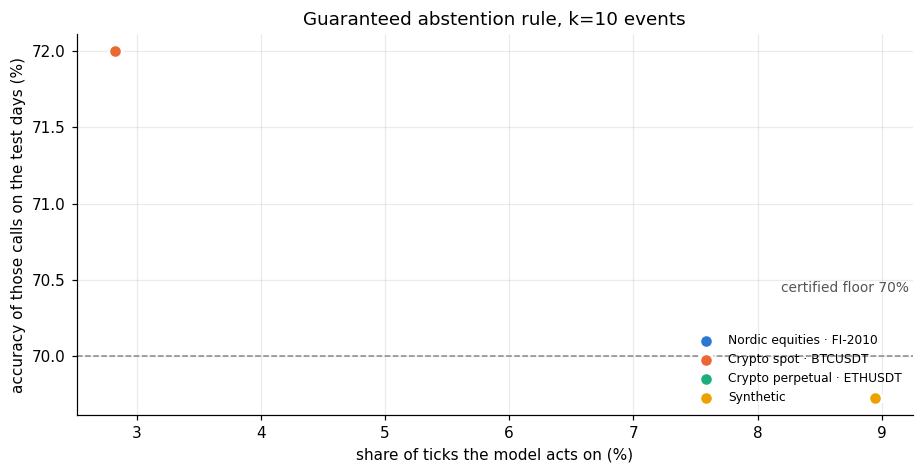

In [15]:
rel = pd.DataFrame([r for v in mk_info.values() for r in v["reliability"]])
rel.round(4).to_csv(RES / "reliability_markets.csv", index=False)
show = rel.set_index(["market", "k"])
display(show[["temperature", "ECE_raw", "ECE_calibrated", "conformal_coverage@90%", "avg_set_size"]].round(3))
display(show[["singleton_up/down_share", "singleton_up/down_accuracy", "guaranteed_tau", "acted_share", "acted_accuracy"]].round(3))
drift_t = pd.DataFrame([v["drift"] for v in mk_info.values()]).set_index("market")
drift_t.to_csv(RES / "drift_markets.csv")
display(drift_t.round(3))

# chart: for each market, accuracy of directional calls vs share of ticks acted on, with the certified rule marked
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for c_, (name, keep) in zip(COLORS, mk_keep.items()):
    r = rel[(rel.market == name) & (rel.k == HORIZONS[0])].iloc[0]
    ax.scatter(r["acted_share"] * 100, r["acted_accuracy"] * 100 if r["acted_share"] > 0 else np.nan, s=80, color=c_,
               edgecolor="white", linewidth=2, label=f"{name.split(' (')[0]}", zorder=3)
ax.axhline(70, color="#888", lw=1, ls="--")
ax.text(ax.get_xlim()[1], 70.4, "certified floor 70% ", ha="right", va="bottom", color="#555", fontsize=9)
ax.set(xlabel="share of ticks the model acts on (%)", ylabel="accuracy of those calls on the test days (%)",
       title=f"Guaranteed abstention rule, k={HORIZONS[0]} events")
ax.legend(frameon=False, fontsize=8, loc="lower right")
plt.tight_layout(); plt.savefig(RES / "guaranteed_rule.png"); plt.show()

### Cross-market comparison
Macro-F1 at k = 10 events for each market. Dots on the same row compare models on one market. The grey tick marks the *best naive baseline* (majority or persistence), so the distance from it is the real edge.

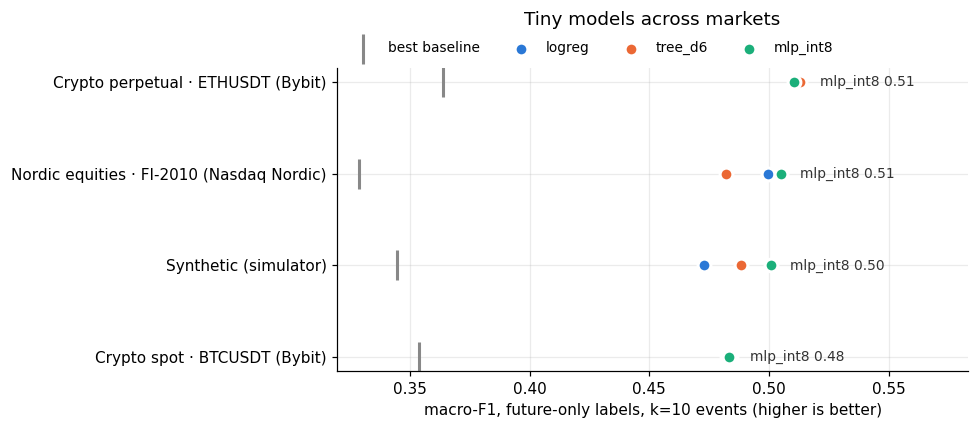

saved results/markets_summary.csv and results/markets_macro_f1.png


In [16]:
MODELS = ["logreg", "tree_d6", "mlp_int8"]
h = HORIZONS[0]
t_ = base[base.k == h].pivot_table(index="market", columns="model", values="macro_f1")
t_ = t_.loc[t_["mlp_int8"].sort_values().index]
fig, ax = plt.subplots(figsize=(9, 0.6 * len(t_) + 1.6))
y_ = np.arange(len(t_))
ax.scatter(t_[["majority", "persistence"]].max(axis=1), y_, marker="|", s=400, color="#888", linewidth=2,
           label="best baseline", zorder=2)
for c_, m_ in zip(COLORS, MODELS):
    ax.scatter(t_[m_], y_, s=70, color=c_, label=m_, edgecolor="white", linewidth=2, zorder=3)
for yy, v, right in zip(y_, t_["mlp_int8"], t_[MODELS].max(axis=1)):
    ax.text(right + 0.008, yy, f"mlp_int8 {v:.2f}", va="center", fontsize=9, color="#333")
ax.set_xlim(right=t_[MODELS].max().max() + 0.07)
ax.set_yticks(y_, t_.index)
ax.set(xlabel=f"macro-F1, future-only labels, k={h} events (higher is better)", )
ax.set_title("Tiny models across markets", pad=28)
ax.legend(frameon=False, loc="lower left", bbox_to_anchor=(0, 1.0), ncol=4, fontsize=9)
plt.tight_layout(); plt.savefig(RES / "markets_macro_f1.png"); plt.show()
print("saved results/markets_summary.csv and results/markets_macro_f1.png")

### FI-2010's official labels leak

FI-2010 also ships official labels, which most published results use. The test below shows that in this widely used copy, the official label mostly records the move that has **already happened**. P(label = up | the mid has just moved up) is far above P(label = up | the next move is up). The future-only labels behave the other way round. Any model that sees the last mid change therefore looks excellent on official labels, including the trivial *persistence* rule. That's why every market above uses future-only labels, and why published FI-2010 scores (e.g. DeepLOB's ~83% F1 at k = 10) should be read with care.

In [17]:
if FI_NAME in mk_keep:
    kf = mk_keep[FI_NAME]
    Xb_, Eb_ = kf["Xb"], kf["Eb"]
    last_up, next_up = Xb_[:, 8] > 0, np.r_[Xb_[1:, 8] > 0, False]
    print("Test days 8-10:           P(up | mid JUST moved up)   P(up | NEXT move is up)")
    off_rows = []
    for j, h in enumerate(FI_COL):
        y_off = Eb_[:, j]
        print(f"  official labels k={h:<3d}          {np.mean(y_off[last_up] == 2):.3f}                    {np.mean(y_off[next_up] == 2):.3f}")
        P_, ex_ = fit_eval(kf["Za"], kf["Ea"][:, j], kf["cut"], kf["Zb"], Xb_, kf["Xa"], kf["mu"], kf["sd"])
        off_rows += [r for r in score(FI_NAME, h, "official", P_, tm.softmax(ex_["z_test"]), y_off) if "@" not in r["model"]]
    off = pd.DataFrame(off_rows).pivot_table(index="model", columns="k", values="macro_f1")
    fut_ = base[base.market == FI_NAME].pivot_table(index="model", columns="k", values="macro_f1")
    print("\nFI-2010 macro-F1, official (leaky) vs future-only labels:")
    display(pd.concat({"official": off, "future-only": fut_}, axis=1).round(3))

Test days 8-10:           P(up | mid JUST moved up)   P(up | NEXT move is up)
  official labels k=10           0.962                    0.370


  official labels k=50           0.691                    0.634



FI-2010 macro-F1, official (leaky) vs future-only labels:


official        future-only       
k                 10     50          10     50
model                                         
logreg         0.776  0.832       0.499  0.454
majority       0.276  0.144       0.225  0.218
mlp_int8       0.799  0.834       0.505  0.464
persistence    0.798  0.472       0.329  0.318
tree_d6        0.801  0.834       0.482  0.430

## 12. Deployment: integer-only kernel and C export

The model that ships is **integer-only**. It is the same network after the float step that scales the inputs:
* the 15 features are scaled and rounded to int8 (one float multiply each);
* hidden layers use int8 weights and activations, int32 accumulators, and fixed-point requantisation (a Q31 multiplier and a right shift per neuron, as in TFLite-Micro), with per-neuron weight scales;
* the output layer shares one scale across the classes, so the class is the argmax of int32 logits and needs no rescaling.

Activation ranges are calibrated on training data. The same arithmetic runs in three places, which must agree **bit for bit**: a vectorised numpy reference, an allocation-free numba kernel (preallocated buffers, nothing created per tick), and a **generated C header** (`c/tinyml_model.h`), compiled with `zig cc` and checked against Python on a recorded stream.

In [18]:
import subprocess, sys
# 1. integer-only quantisation of the trained network, calibrated on training features
QM = tm.quantize_mlp(WS, mu, sd, X_raw[tr])
_, p_q = tm.qmlp_forward(QM, X_raw[te])
yt_ = Y[H_MAIN][te]
dep = pd.DataFrame({
    "accuracy": [accuracy_score(yt_, preds[H_MAIN][m]) for m in ("mlp_fp32", "mlp_int8")] + [accuracy_score(yt_, p_q)],
    "macro_f1": [f1_score(yt_, preds[H_MAIN][m], average="macro") for m in ("mlp_fp32", "mlp_int8")] + [f1_score(yt_, p_q, average="macro")],
    "agrees_with_fp32": [1.0, (preds[H_MAIN]["mlp_int8"] == preds[H_MAIN]["mlp_fp32"]).mean(), (p_q == preds[H_MAIN]["mlp_fp32"]).mean()],
}, index=["fp32", "int8 weights (float maths)", "integer-only int8"]).round(4)
display(dep)

# 2. streaming parity: the allocation-free numba pipeline == the vectorised reference, tick by tick
R_last = Rs[-1]
p_stream = tm.run_pipeline(R_last, TICK, QM["mu"], QM["a"], *QM["P"])
_, p_ref = tm.qmlp_forward(QM, tm.run_features(R_last, TICK))
assert (p_stream == p_ref).all()
print(f"numba streaming pipeline == reference on {len(R_last):,} ticks")

# 3. numba latency, allocation-free
st_, xb_, xq_, h1_, h2_, lg_ = tm.buffers(QM)
lat_q = bench(lambda r: tm.tick_predict(st_, r, TICK, QM["mu"], QM["a"], xb_, xq_, *QM["P"], h1_, h2_, lg_), R_last)
k_q = kernel_ns(tm.run_pipeline, R_last, TICK, QM["mu"], QM["a"], *QM["P"])

# 4. C: generate the header, compile, check parity on the recorded stream, time it
Path("c").mkdir(exist_ok=True)
tm.export_c(QM, TICK, "c/tinyml_model.h", f"Trained on {SOURCE} data, horizon {H_MAIN} events.")
n_c = min(len(R_last), 50_000)
np.ascontiguousarray(R_last[:n_c]).tofile("c/rows.bin"); p_stream[:n_c].astype(np.int8).tofile("c/expected.bin")
cc = subprocess.run([sys.executable, "-m", "ziglang", "cc", "-O2", "-march=native", "-ffp-contract=off",
                     "-o", "c/bench.exe", "c/bench.c"], capture_output=True, text=True)
assert cc.returncode == 0, cc.stderr
out = subprocess.run([str(Path("c/bench.exe").resolve()), "c/rows.bin", "c/expected.bin", str(n_c)],
                     capture_output=True, text=True).stdout
cres = {k: float(v) for k, v in (l.split() for l in out.strip().splitlines())}
assert cres["mismatches"] == 0, "C and Python disagree"
print(f"C header == Python on {n_c:,} ticks (0 mismatches)")

deploy = pd.DataFrame([
    {"path": "numba MLP int8 weights, float maths (section 7)", "p50_us": latdf.loc["mlp_int8 (numba)", "p50_us"],
     "p99_us": latdf.loc["mlp_int8 (numba)", "p99_us"], "in_kernel_ns": latdf.loc["mlp_int8 (numba)", "in_kernel_ns"]},
    {"path": "numba full tick, float model (section 7)", "p50_us": latdf.loc["pipeline: features+z+mlp_int8 (numba)", "p50_us"],
     "p99_us": latdf.loc["pipeline: features+z+mlp_int8 (numba)", "p99_us"],
     "in_kernel_ns": latdf.loc["pipeline: features+z+mlp_int8 (numba)", "in_kernel_ns"]},
    {"path": "numba full tick, integer-only, allocation-free", "p50_us": lat_q[0], "p99_us": lat_q[1], "in_kernel_ns": k_q},
    {"path": "C model only, integer-only", "p50_us": np.nan, "p99_us": np.nan, "in_kernel_ns": cres["model_ns"]},
    {"path": "C full tick: features + integer-only model", "p50_us": cres["p50_ns"] / 1000, "p99_us": cres["p99_ns"] / 1000,
     "in_kernel_ns": cres["tick_ns"]},
]).set_index("path")
deploy.round(3).to_csv(RES / "deployment_latency.csv")
display(deploy.round(3))
print("C per-call figures use the CPU cycle counter (includes its ~10 ns read cost); p99.9 =",
      f"{cres['p999_ns']:.0f} ns")

mb = tm.model_bytes(QM)
hdr = Path("c/tinyml_model.h").stat().st_size
print(f"deployed model: {mb['weights_int8']} B int8 weights + {mb['bias_int32']} B biases + {mb['requant_int32+shift']} B requant"
      f" + {mb['input_scaling_f32']} B input scaling = {sum(v for k, v in mb.items() if k != 'macs')} B;"
      f" {mb['macs']} multiply-adds per prediction; state {tm.ST_SIZE} doubles ({8 * tm.ST_SIZE} B); header source {hdr:,} B")
print(f"microcontroller budget (estimate, 1 multiply-add per cycle, no SIMD): ~{mb['macs']} cycles for the model,"
      f" about {mb['macs'] / 168:.1f} µs on a 168 MHz Cortex-M4")
np.savez(MOD / "tinyml_int8.npz", mu=QM["mu"], a=QM["a"], tick=TICK, horizon=H_MAIN,
         **{k: v for k, v in zip(["W1", "b1", "m1", "r1", "W2", "b2", "m2", "r2", "W3", "b3"], QM["P"])})

,accuracy,macro_f1,agrees_with_fp32
fp32,0.4997,0.4976,1.0000
int8 weights (float maths),0.5003,0.4981,0.9954
integer-only int8,0.5009,0.4986,0.9894


numba streaming pipeline == reference on 60,000 ticks


C header == Python on 50,000 ticks (0 mismatches)


,p50_us,p99_us,in_kernel_ns
path,,,
"numba MLP int8 weights, float maths (section 7)",1.70,2.2,253.151
"numba full tick, float model (section 7)",1.60,3.0,461.755
"numba full tick, integer-only, allocation-free",3.20,4.3,394.702
"C model only, integer-only",NaN,NaN,31.260
C full tick: features + integer-only model,0.12,0.2,135.830


C per-call figures use the CPU cycle counter (includes its ~10 ns read cost); p99.9 = 351 ns
deployed model: 232 B int8 weights + 76 B biases + 80 B requant + 144 B input scaling = 532 B; 232 multiply-adds per prediction; state 75 doubles (600 B); header source 4,563 B
microcontroller budget (estimate, 1 multiply-add per cycle, no SIMD): ~232 cycles for the model, about 1.4 µs on a 168 MHz Cortex-M4


## 13. Teacher vs student, quantisation, size–speed search, feature importance, decision value

These come from `python experiments.py`, which runs the heavier studies for every real market (horizon k = 10, same chronological splits and future-only labels) and writes `results/experiments/`.

* **Teacher vs student.** A DeepLOB-style teacher (temporal convolutions + GRU over the last 50 book events, using all 18 features plus the raw 5-level book shape, about 25k parameters, fp32) against the integer-only student (width 8, about 0.5 KB). The student is trained on labels alone, then again with **knowledge distillation** from the teacher (Hinton et al.: labels mixed with the teacher's softened probabilities, λ = 0.5, T = 2).
* **Quantisation-aware training.** Post-training quantisation against QAT (fake-quantised weights with a straight-through estimator) at 8-bit and 4-bit weights.
* **Size–speed search.** Hidden width {4, 8, 16, 32} × top-{6, 10, 18} features by importance, each quantised and timed. The Pareto frontier is the set of models that no smaller model beats.
* **Feature importance.** Macro-F1 lost on the calibration set when one feature is shuffled.
* **Decision value (research only, no trading).** For the most confident directional calls: the average move in the predicted direction (gross edge, in ticks) against the spread a trade would cross. Also how much of that edge survives if the prediction arrives 1–20 book events late, which is the link between latency and value.

Teacher vs student (same test rows; latency = one prediction, single thread):


params  \
market                                    model                                          
Nordic equities · FI-2010 (Nasdaq Nordic) teacher: DeepLOB-style CNN+GRU, fp32   25795   
                                          student: int8 MLP                        627   
                                          student distilled: int8 MLP              627   
Crypto spot · BTCUSDT (Bybit)             teacher: DeepLOB-style CNN+GRU, fp32   25795   
                                          student: int8 MLP                        627   
                                          student distilled: int8 MLP              627   
Crypto perpetual · ETHUSDT (Bybit)        teacher: DeepLOB-style CNN+GRU, fp32   25795   
                                          student: int8 MLP                        627   
                                          student distilled: int8 MLP              627   

                                                                                 bytes  \
market                                    model                                          
Nordic equities · FI-2010 (Nasdaq Nordic) teacher: DeepLOB-style CNN+GRU, fp32  103180   
                                          student: int8 MLP                       1036   
                                          student distilled: int8 MLP             1036   
Crypto spot · BTCUSDT (Bybit)             teacher: DeepLOB-style CNN+GRU, fp32  103180   
                                          student: int8 MLP                       1036   
                                          student distilled: int8 MLP             1036   
Crypto perpetual · ETHUSDT (Bybit)        teacher: DeepLOB-style CNN+GRU, fp32  103180   
                                          student: int8 MLP                       1036   
                                          student distilled: int8 MLP             1036   

                                                                                macro_f1  \
market                                    model                                            
Nordic equities · FI-2010 (Nasdaq Nordic) teacher: DeepLOB-style CNN+GRU, fp32    0.5156   
                                          student: int8 MLP                       0.5067   
                                          student distilled: int8 MLP             0.5046   
Crypto spot · BTCUSDT (Bybit)             teacher: DeepLOB-style CNN+GRU, fp32    0.5063   
                                          student: int8 MLP                       0.4846   
                                          student distilled: int8 MLP             0.4892   
Crypto perpetual · ETHUSDT (Bybit)        teacher: DeepLOB-style CNN+GRU, fp32    0.5365   
                                          student: int8 MLP                       0.5016   
                                          student distilled: int8 MLP             0.5174   

                                                                                accuracy  \
market                                    model                                            
Nordic equities · FI-2010 (Nasdaq Nordic) teacher: DeepLOB-style CNN+GRU, fp32    0.5595   
                                          student: int8 MLP                       0.5338   
                                          student distilled: int8 MLP             0.5406   
Crypto spot · BTCUSDT (Bybit)             teacher: DeepLOB-style CNN+GRU, fp32    0.5883   
                                          student: int8 MLP                       0.5698   
                                          student distilled: int8 MLP             0.5666   
Crypto perpetual · ETHUSDT (Bybit)        teacher: DeepLOB-style CNN+GRU, fp32    0.5944   
                                          student: int8 MLP                       0.5863   
                                          student distilled: int8 MLP             0.5879   

                                                                        

Quantisation: post-training (PTQ) vs quantisation-aware training (QAT), macro-F1:


float_f1  PTQ_f1  \
market                                    weight_bits                     
Nordic equities · FI-2010 (Nasdaq Nordic) 8              0.5070  0.5070   
                                          4              0.5070  0.5033   
Crypto spot · BTCUSDT (Bybit)             8              0.4892  0.4892   
                                          4              0.4892  0.4877   
Crypto perpetual · ETHUSDT (Bybit)        8              0.5173  0.5173   
                                          4              0.5173  0.5275   

                                                       QAT_f1  
market                                    weight_bits          
Nordic equities · FI-2010 (Nasdaq Nordic) 8            0.5059  
                                          4            0.5053  
Crypto spot · BTCUSDT (Bybit)             8            0.4887  
                                          4            0.4810  
Crypto perpetual · ETHUSDT (Bybit)        8            0.5076  
                                          4            0.5051

Size-speed search (frontier models marked):


macs  bytes  \
market                                    features width                
Crypto perpetual · ETHUSDT (Bybit)        6        4        52    184   
                                          10       4        68    232   
                                          18       4       100    328   
                                          6        8       136    340   
                                          10       8       168    404   
                                          18       8       232    532   
                                          6        16      400    748   
                                          10       16      464    844   
                                          18       16      592   1036   
                                          6        32     1312   1948   
                                          10       32     1440   2108   
                                          18       32     1696   2428   
Crypto spot · BTCUSDT (Bybit)             6        4        52    184   
                                          10       4        68    232   
                                          18       4       100    328   
                                          6        8       136    340   
                                          10       8       168    404   
                                          18       8       232    532   
                                          6        16      400    748   
                                          10       16      464    844   
                                          18       16      592   1036   
                                          6        32     1312   1948   
                                          10       32     1440   2108   
                                          18       32     1696   2428   
Nordic equities · FI-2010 (Nasdaq Nordic) 6        4        52    184   
                                          10       4        68    232   
                                          18       4       100    328   
                                          6        8       136    340   
                                          10       8       168    404   
                                          18       8       232    532   
                                          6        16      400    748   
                                          10       16      464    844   
                                          18       16      592   1036   
                                          6        32     1312   1948   
                                          10       32     1440   2108   
                                          18       32     1696   2428   

                                                          model_ns  macro_f1  \
market                                    features width                       
Crypto perpetual · ETHUSDT (Bybit)        6        4        93.188    0.5052   
                                          10       4        96.384    0.4907   
                                          18       4       112.712    0.5045   
                                          6        8       122.232    0.5065   
                                          10       8       128.224    0.5068   
                                          18       8       148.056    0.5068   
                                          6        16      174.508    0.4958   
                                          10       16      195.358    0.5073   
                                          18       16      244.888    0.5015   
                                          6        32      313.282    0.5093   
                                          10       32      352.332    0.4987   
                                          18       32      461.170    0.5155   
Crypto spot · BTCUSDT (Bybit)             6        4        96.580    0.4839   
                                          10       4       103.086    0.4780   
   

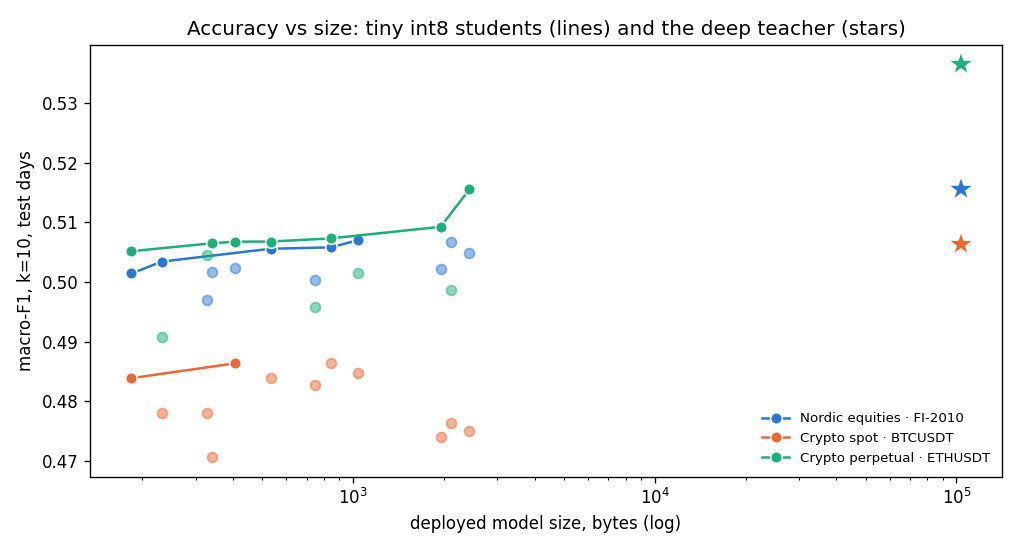

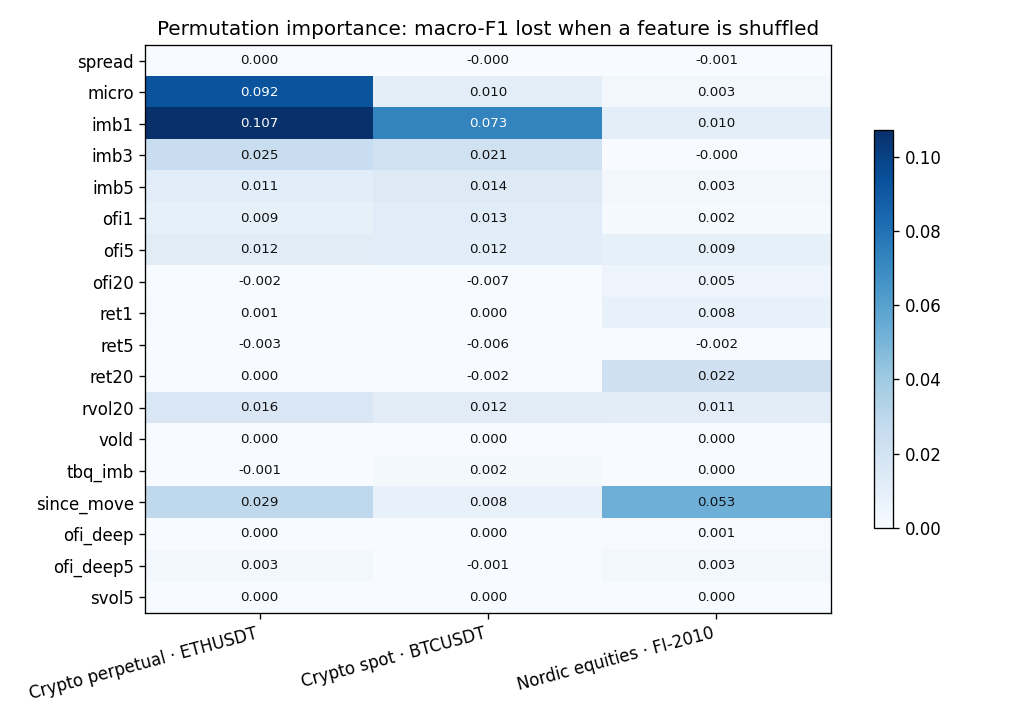

Decision value of confident calls (research only; ticks):


share_of_ticks  \
market                                    kept_top                              
Nordic equities · FI-2010 (Nasdaq Nordic) 100% of directional           0.545   
                                          50% of directional            0.273   
                                          25% of directional            0.136   
                                          10% of directional            0.055   
                                          5% of directional             0.027   
                                          1% of directional             0.005   
Crypto spot · BTCUSDT (Bybit)             100% of directional           0.309   
                                          50% of directional            0.155   
                                          25% of directional            0.077   
                                          10% of directional            0.031   
                                          5% of directional             0.015   
                                          1% of directional             0.003   
Crypto perpetual · ETHUSDT (Bybit)        100% of directional           0.332   
                                          50% of directional            0.166   
                                          25% of directional            0.083   
                                          10% of directional            0.033   
                                          5% of directional             0.017   
                                          1% of directional             0.003   

                                                                calls  \
market                                    kept_top                      
Nordic equities · FI-2010 (Nasdaq Nordic) 100% of directional   75883   
                                          50% of directional    37942   
                                          25% of directional    18971   
                                          10% of directional     7589   
                                          5% of directional      3795   
                                          1% of directional       759   
Crypto spot · BTCUSDT (Bybit)             100% of directional  154381   
                                          50% of directional    77191   
                                          25% of directional    38596   
                                          10% of directional    15439   
                                          5% of directional      7720   
                                          1% of directional      1544   
Crypto perpetual · ETHUSDT (Bybit)        100% of directional  254691   
                                          50% of directional   127346   
                                          25% of directional    63673   
                                          10% of directional    25470   
                                          5% of directional     12735   
                                          1% of directional      2547   

                                                               hit_rate  \
market                                    kept_top                        
Nordic equities · FI-2010 (Nasdaq Nordic) 100% of directional     0.425   
                                          50% of directional      0.483   
                                          25% of directional      0.528   
                                          10% of directional      0.580   
                                          5% of directional       0.607   
                                          1% of directional       0.655   
Crypto spot · BTCUSDT (Bybit)             100% of directional     0.511   
                                          50% of directional      0.594   
                                          25% of directional      0.658   
                                          10% of directional      0.734   
                                          5% of directional       0.772   
      

gross_edge_ticks  \
market                                    delay_events                     
Nordic equities · FI-2010 (Nasdaq Nordic) 0                        0.489   
                                          1                        0.375   
                                          2                        0.322   
                                          5                        0.223   
                                          10                       0.135   
                                          20                       0.036   
Crypto spot · BTCUSDT (Bybit)             0                       34.395   
                                          1                       15.823   
                                          2                       11.310   
                                          5                        7.006   
                                          10                       4.585   
                                          20                       1.537   
Crypto perpetual · ETHUSDT (Bybit)        0                       10.681   
                                          1                        4.801   
                                          2                        2.920   
                                          5                        0.849   
                                          10                       0.832   
                                          20                       0.311   

                                                        accuracy  calls  
market                                    delay_events                   
Nordic equities · FI-2010 (Nasdaq Nordic) 0                0.580   7589  
                                          1                0.511   7589  
                                          2                0.476   7589  
                                          5                0.427   7587  
                                          10               0.377   7585  
                                          20               0.320   7579  
Crypto spot · BTCUSDT (Bybit)             0                0.734  15439  
                                          1                0.506  15439  
                                          2                0.448  15439  
                                          5                0.396  15439  
                                          10               0.363  15439  
                                          20               0.320  15439  
Crypto perpetual · ETHUSDT (Bybit)        0                0.698  25470  
                                          1                0.529  25470  
                                          2                0.475  25470  
                                          5                0.415  25470  
                                          10               0.390  25470  
                                          20               0.366  25470

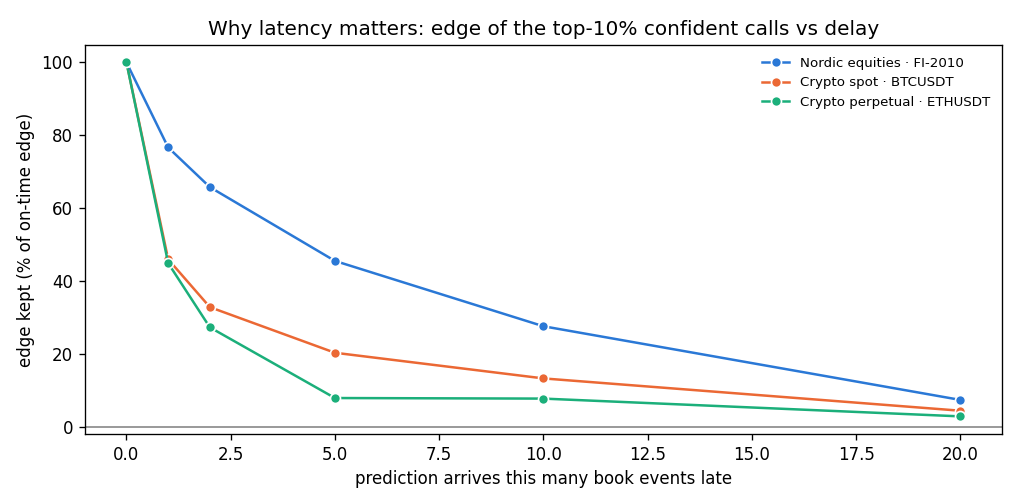

In [19]:
from IPython.display import Image
EXP = Path("results/experiments")
if not (EXP / "teacher.csv").exists():
    print("Run `python experiments.py` first (about 15-30 minutes on a laptop CPU).")
else:
    tvs = pd.read_csv(EXP / "teacher.csv")
    print("Teacher vs student (same test rows; latency = one prediction, single thread):")
    display(tvs.drop(columns="note").round(4).set_index(["market", "model"]))
    print("Quantisation: post-training (PTQ) vs quantisation-aware training (QAT), macro-F1:")
    display(pd.read_csv(EXP / "qat.csv").round(4).set_index(["market", "weight_bits"]))
    par = pd.read_csv(EXP / "pareto.csv")
    print("Size-speed search (frontier models marked):")
    par = par.sort_values(["market", "bytes"])
    par["frontier"] = par.groupby("market").macro_f1.transform(lambda s: s >= s.cummax())
    display(par.drop(columns="feature_set").round(4).set_index(["market", "features", "width"]))
    display(Image(EXP / "pareto.png"))
    display(Image(EXP / "importance.png"))
    print("Decision value of confident calls (research only; ticks):")
    display(pd.read_csv(EXP / "sim.csv").round(3).set_index(["market", "kept_top"]))
    display(pd.read_csv(EXP / "delay.csv").round(3).set_index(["market", "delay_events"]))
    display(Image(EXP / "latency_decay.png"))

## 14. Reading the results
* **Accuracy:** the models should be compared with the *best baseline*, not with 33%. A real edge on NIFTY futures at h=10 updates usually shows up as a few points of accuracy over persistence, with most of the gain in the most confident predictions (section 9).
* **Latency:** the deployed integer-only model in C runs the full per-tick path (features + model) in about 0.15 µs, matching Python bit for bit (section 12). The Python per-call numbers are dominated by dispatch, not by the model. sklearn and torch single-sample calls cost tens of microseconds, which is why the numba re-implementation is the deployable artifact.
* **Size:** every deployable model is under 3 KB, small enough for L1 cache or a microcontroller.
* **On real data:** record several sessions with `collect_kite.py` / `collect_upstox.py` and re-run. The notebook switches automatically. Expect lower accuracy than on the simulator, and check per-session stability before trusting any number.
* **Across markets (section 11):** compare each market with its own best baseline. Event rates, tick sizes and queue depths differ a lot between NIFTY futures, Nordic stocks and crypto, so absolute scores differ too. What should hold everywhere is a positive gap over the baselines, plus higher accuracy when only the most confident predictions are used. Judge results on future-only labels, never on FI-2010's official ones.